# Predicting Primary School Enrollment Rates in Africa

## 1. Project Introduction

### Problem Statement
Primary school enrollment rates vary across African countries due to differences in economic conditions, population growth and educational resources. This project uses machine learning to explore these relationships and predict enrollment rates.

### Objective
Develop and compare four regression models:
- SGDRegressor
- Linear Regression
- Decision Tree Regressor
- Random Forest Regressor

Evaluate their performance using Mean Squared Error (MSE) and select the best-performing model.

### Dataset
- **Source:** [World Bank Education Statistics](https://www.kaggle.com/datasets/theworldbank/education-statistics)
- **Geographic focus:** African countries
- **Historical period:** 1970–2017
- **Target variable:** Primary school gross enrollment ratio (%)
- **Task:** Multivariate regression

### Expected Outcome
Deploy the best-performing model through a FastAPI backend and integrate it with a Flutter mobile application for enrollment predictions.

## 2. Import Libraries

Import the necessary Python libraries for data manipulation, numerical computations, data visualization, machine learning and model evaluation.

In [149]:

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os

import joblib


## 3. Data Loading and Initial Inspection

The World Bank Education Statistics datasets are loaded from Google Drive. Initial inspection is performed to understand their dimensions, column names, data types and missing values.

3.1 Mount Google Drive

In [150]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


3.2 Define your dataset path

In [151]:
data_path = '/content/drive/MyDrive/linear_regression_model/summative/datasets/'

3.3 Load the datasets

In [152]:
# Load the main education dataset
education_data = pd.read_csv(os.path.join(data_path, 'EdStatsData.csv'))

# Load country metadata
country_data = pd.read_csv(os.path.join(data_path, 'EdStatsCountry.csv'))

# Load indicator metadata
series_data = pd.read_csv(os.path.join(data_path, 'EdStatsSeries.csv'))

print("All datasets loaded successfully.")

All datasets loaded successfully.


3.4 Inspect dataset dimensions

In [153]:
print("Education data shape:", education_data.shape)
print("Country data shape:", country_data.shape)
print("Series data shape:", series_data.shape)

Education data shape: (886930, 70)
Country data shape: (241, 32)
Series data shape: (3665, 21)


3.5 Preview the main education dataset

In [154]:
education_data.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1970,1971,1972,1973,1974,1975,...,2060,2065,2070,2075,2080,2085,2090,2095,2100,Unnamed: 69
0,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.F,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.GPI,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.M,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Arab World,ARB,"Adjusted net enrolment rate, primary, both sex...",SE.PRM.TENR,54.822121,54.894138,56.209438,57.267109,57.991138,59.36554,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [155]:
country_data.head()

,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,...,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data,Unnamed: 31
0,ABW,Aruba,Aruba,Aruba,AW,Aruban florin,SNA data for 2000-2011 are updated from offici...,Latin America & Caribbean,High income: nonOECD,AW,...,NaN,2010,NaN,NaN,Yes,NaN,NaN,2012.0,NaN,NaN
1,AFG,Afghanistan,Afghanistan,Islamic State of Afghanistan,AF,Afghan afghani,Fiscal year end: March 20; reporting period fo...,South Asia,Low income,AF,...,General Data Dissemination System (GDDS),1979,"Multiple Indicator Cluster Survey (MICS), 2010/11","Integrated household survey (IHS), 2008",NaN,2013/14,NaN,2012.0,2000,NaN
2,AGO,Angola,Angola,People's Republic of Angola,AO,Angolan kwanza,"April 2013 database update: Based on IMF data,...",Sub-Saharan Africa,Upper middle income,AO,...,General Data Dissemination System (GDDS),1970,"Malaria Indicator Survey (MIS), 2011","Integrated household survey (IHS), 2008",NaN,2015,NaN,NaN,2005,NaN
3,ALB,Albania,Albania,Republic of Albania,AL,Albanian lek,NaN,Europe & Central Asia,Upper middle income,AL,...,General Data Dissemination System (GDDS),2011,"Demographic and Health Survey (DHS), 2008/09",Living Standards Measurement Study Survey (LSM...,Yes,2012,2010.0,2012.0,2006,NaN
4,AND,Andorra,Andorra,Principality of Andorra,AD,Euro,NaN,Europe & Central Asia,High income: nonOECD,AD,...,NaN,2011. Population figures compiled from adminis...,NaN,NaN,Yes,NaN,NaN,2006.0,NaN,NaN


In [156]:
series_data.head()

,Series Code,Topic,Indicator Name,Short definition,Long definition,Unit of measure,Periodicity,Base Period,Other notes,Aggregation method,...,Notes from original source,General comments,Source,Statistical concept and methodology,Development relevance,Related source links,Other web links,Related indicators,License Type,Unnamed: 20
0,BAR.NOED.1519.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...,Percentage of female population age 15-19 with...,Percentage of female population age 15-19 with...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,BAR.NOED.1519.ZS,Attainment,Barro-Lee: Percentage of population age 15-19 ...,Percentage of population age 15-19 with no edu...,Percentage of population age 15-19 with no edu...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,BAR.NOED.15UP.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...,Percentage of female population age 15+ with n...,Percentage of female population age 15+ with n...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,BAR.NOED.15UP.ZS,Attainment,Barro-Lee: Percentage of population age 15+ wi...,Percentage of population age 15+ with no educa...,Percentage of population age 15+ with no educa...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,BAR.NOED.2024.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...,Percentage of female population age 20-24 with...,Percentage of female population age 20-24 with...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN


3.6 Inspect column names

In [157]:
print("Education data columns:")
print(education_data.columns.tolist())

print("\nCountry data columns:")
print(country_data.columns.tolist())

print("\nSeries data columns:")
print(series_data.columns.tolist())

Education data columns:
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2020', '2025', '2030', '2035', '2040', '2045', '2050', '2055', '2060', '2065', '2070', '2075', '2080', '2085', '2090', '2095', '2100', 'Unnamed: 69']

Country data columns:
['Country Code', 'Short Name', 'Table Name', 'Long Name', '2-alpha code', 'Currency Unit', 'Special Notes', 'Region', 'Income Group', 'WB-2 code', 'National accounts base year', 'National accounts reference year', 'SNA price valuation', 'Lending category', 'Other groups', 'System of National Accounts', 'Alternative conversion factor', 'PPP survey 

3.7 Inspect data types

In [158]:
education_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 886930 entries, 0 to 886929
Data columns (total 70 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Country Name    886930 non-null  object 
 1   Country Code    886930 non-null  object 
 2   Indicator Name  886930 non-null  object 
 3   Indicator Code  886930 non-null  object 
 4   1970            72288 non-null   float64
 5   1971            35537 non-null   float64
 6   1972            35619 non-null   float64
 7   1973            35545 non-null   float64
 8   1974            35730 non-null   float64
 9   1975            87306 non-null   float64
 10  1976            37483 non-null   float64
 11  1977            37574 non-null   float64
 12  1978            37576 non-null   float64
 13  1979            36809 non-null   float64
 14  1980            89122 non-null   float64
 15  1981            38777 non-null   float64
 16  1982            37511 non-null   float64
 17  1983      

4.8 inspect missing values

In [159]:
education_data.isnull().sum()

,0
Country Name,0
Country Code,0
Indicator Name,0
Indicator Code,0
1970,814642
...,...
2085,835494
2090,835494
2095,835494
2100,835494


4.9 check for duplicate records

In [160]:
print("Duplicate education records:", education_data.duplicated().sum())

print("Duplicate country records:", country_data.duplicated().sum())

print("Duplicate indicator records:", series_data.duplicated().sum())

Duplicate education records: 0
Duplicate country records: 0
Duplicate indicator records: 0


Section 4 — Data Preparation
This is one of the most important sections of your assignment. We will transform the original World Bank dataset into a structured dataset suitable for multivariate regression.

## 4. Data Preparation

The dataset is prepared for regression by filtering African countries, selecting relevant education and socioeconomic indicators, restructuring the data into country-year observations, merging country metadata and handling missing values.

### 4.1 Filter African Countries

Identify geographic regions

Before filtering, we need to understand how the World Bank classifies countries geographically.








In [161]:
country_data['Region'].value_counts()

,count
Region,
Europe & Central Asia,57
Sub-Saharan Africa,48
Latin America & Caribbean,41
East Asia & Pacific,36
Middle East & North Africa,21
South Asia,8
North America,3


 Inspect African country metadata
We need to identify countries belonging to Sub-Saharan Africa and the African countries classified under Middle East and North Africa.

In [162]:
country_data[['Country Code', 'Short Name', 'Region', 'Income Group']].head(20)

,Country Code,Short Name,Region,Income Group
0,ABW,Aruba,Latin America & Caribbean,High income: nonOECD
1,AFG,Afghanistan,South Asia,Low income
2,AGO,Angola,Sub-Saharan Africa,Upper middle income
3,ALB,Albania,Europe & Central Asia,Upper middle income
4,AND,Andorra,Europe & Central Asia,High income: nonOECD
5,ARB,Arab World,NaN,NaN
6,ARE,United Arab Emirates,Middle East & North Africa,High income: nonOECD
7,ARG,Argentina,Latin America & Caribbean,Upper middle income
8,ARM,Armenia,Europe & Central Asia,Lower middle income
9,ASM,American Samoa,East Asia & Pacific,Upper middle income


In [163]:
north_african_codes = ['DZA', 'DJI', 'EGY', 'LBY', 'MAR', 'TUN']

In [164]:
african_countries = country_data[
    (country_data['Region'] == 'Sub-Saharan Africa') |
    (country_data['Country Code'].isin(north_african_codes))
].copy()

In [165]:
print("Number of African countries:", african_countries['Country Code'].nunique())

african_countries[
    ['Country Code', 'Short Name', 'Region', 'Income Group']
]

Number of African countries: 54


,Country Code,Short Name,Region,Income Group
2,AGO,Angola,Sub-Saharan Africa,Upper middle income
14,BDI,Burundi,Sub-Saharan Africa,Low income
16,BEN,Benin,Sub-Saharan Africa,Low income
17,BFA,Burkina Faso,Sub-Saharan Africa,Low income
31,BWA,Botswana,Sub-Saharan Africa,Upper middle income
32,CAF,Central African Republic,Sub-Saharan Africa,Low income
38,CIV,Côte d'Ivoire,Sub-Saharan Africa,Lower middle income
39,CMR,Cameroon,Sub-Saharan Africa,Lower middle income
40,COD,Dem. Rep. Congo,Sub-Saharan Africa,Low income
41,COG,Congo,Sub-Saharan Africa,Lower middle income


 4.1.2 — Filter the main education dataset
Now that we have identified the African country codes, we need to filter our main education dataset.

In [166]:
african_country_codes = african_countries['Country Code'].tolist()

african_education_data = education_data[
    education_data['Country Code'].isin(african_country_codes)
].copy()

print("African education data shape:", african_education_data.shape)

African education data shape: (197910, 70)


In [167]:
print("Number of countries:",
      african_education_data['Country Code'].nunique())

print("Number of indicators:",
      african_education_data['Indicator Code'].nunique())

african_education_data.head()

Number of countries: 54
Number of indicators: 3665


,Country Name,Country Code,Indicator Name,Indicator Code,1970,1971,1972,1973,1974,1975,...,2060,2065,2070,2075,2080,2085,2090,2095,2100,Unnamed: 69
98955,Algeria,DZA,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2,NaN,9.17320,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
98956,Algeria,DZA,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.F,NaN,5.65266,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
98957,Algeria,DZA,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.GPI,NaN,0.45049,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
98958,Algeria,DZA,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.M,NaN,12.54784,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
98959,Algeria,DZA,"Adjusted net enrolment rate, primary, both sex...",SE.PRM.TENR,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


4.2 Select Target and Feature Indicators
Now that we have filtered the dataset to African countries, we need to select the indicators that will be used to train our regression models.

The original dataset contains thousands of indicators, but we only need those relevant to predicting primary school enrollment.

In [168]:
selected_indicators = {
    'SE.PRM.ENRR': 'primary_enrollment',
    'SP.POP.TOTL': 'population',
    'SP.POP.GROW': 'population_growth',
    'SE.SEC.ENRR': 'secondary_enrollment',
    'SE.PRM.ENRL.TC.ZS': 'pupil_teacher_ratio',
    'NY.GDP.PCAP.KD': 'gdp_per_capita',
    'SE.PRM.DURS': 'primary_education_duration',
    'SP.POP.0014.TO.ZS': 'population_age_0_14'
}

In [169]:
series_data[
    series_data['Series Code'].isin(selected_indicators.keys())
][['Series Code', 'Indicator Name']]

,Series Code,Indicator Name
1663,NY.GDP.PCAP.KD,GDP per capita (constant 2010 US$)
2245,SE.PRM.DURS,Theoretical duration of primary education (years)
2249,SE.PRM.ENRL.TC.ZS,Pupil-teacher ratio in primary education (head...
2250,SE.PRM.ENRR,"Gross enrolment ratio, primary, both sexes (%)"
2307,SE.SEC.ENRR,"Gross enrolment ratio, secondary, both sexes (%)"
2404,SP.POP.0014.TO.ZS,Population ages 0-14 (% of total)
2589,SP.POP.GROW,Population growth (annual %)
2590,SP.POP.TOTL,"Population, total"


In [170]:
selected_education_data = african_education_data[
    african_education_data['Indicator Code'].isin(selected_indicators.keys())
].copy()

print("Selected education data shape:", selected_education_data.shape)

Selected education data shape: (432, 70)


In [171]:
print("Number of countries:",
      selected_education_data['Country Code'].nunique())

print("Number of selected indicators:",
      selected_education_data['Indicator Code'].nunique())

selected_education_data[
    ['Indicator Code', 'Indicator Name']
].drop_duplicates()

Number of countries: 54
Number of selected indicators: 8


,Indicator Code,Indicator Name
100199,NY.GDP.PCAP.KD,GDP per capita (constant 2005 US$)
100286,SE.PRM.ENRR,"Gross enrolment ratio, primary, both sexes (%)"
100290,SE.SEC.ENRR,"Gross enrolment ratio, secondary, both sexes (%)"
101262,SP.POP.GROW,Population growth (annual %)
101374,SP.POP.0014.TO.ZS,"Population, ages 0-14 (% of total)"
101488,SP.POP.TOTL,"Population, total"
101506,SE.PRM.ENRL.TC.ZS,Pupil-teacher ratio in primary education (head...
101940,SE.PRM.DURS,Theoretical duration of primary education (years)


### 4.3 Select Historical Years

Historical observations from 1970 to 2017 are selected for model development. Future projections and unnecessary columns are excluded to ensure that the regression models are trained on historical data rather than projected values.

In [172]:
historical_years = [str(year) for year in range(1970, 2018)]

print("Number of historical years:", len(historical_years))
print("First year:", historical_years[0])
print("Last year:", historical_years[-1])

Number of historical years: 48
First year: 1970
Last year: 2017


In [173]:
columns_to_keep = [
    'Country Name',
    'Country Code',
    'Indicator Name',
    'Indicator Code'
] + historical_years

historical_data = selected_education_data[columns_to_keep].copy()

print("Historical dataset shape:", historical_data.shape)

historical_data.head()

Historical dataset shape: (432, 52)


,Country Name,Country Code,Indicator Name,Indicator Code,1970,1971,1972,1973,1974,1975,...,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
100199,Algeria,DZA,GDP per capita (constant 2005 US$),NY.GDP.PCAP.KD,2691.802317,2321.350402,2877.745265,2906.700502,3039.420571,3104.493573,...,4390.499633,4386.038896,4463.394675,4504.920098,4564.435017,4596.219627,4675.885024,4759.595242,4827.724251,NaN
100286,Algeria,DZA,"Gross enrolment ratio, primary, both sexes (%)",SE.PRM.ENRR,NaN,74.015533,78.151161,82.824173,86.593620,88.706253,...,109.312057,112.430740,115.454613,116.746918,118.267357,119.751663,118.749474,116.154442,NaN,NaN
100290,Algeria,DZA,"Gross enrolment ratio, secondary, both sexes (%)",SE.SEC.ENRR,NaN,10.036360,12.071720,13.524120,14.747980,16.028271,...,76.755852,93.070030,97.171921,99.860191,NaN,NaN,NaN,NaN,NaN,NaN
101262,Algeria,DZA,Population growth (annual %),SP.POP.GROW,2.827186,2.779393,2.749168,2.741122,2.762508,2.803819,...,1.621298,1.720717,1.821358,1.924787,2.006614,2.036092,2.000666,1.919959,1.825463,NaN
101374,Algeria,DZA,"Population, ages 0-14 (% of total)",SP.POP.0014.TO.ZS,46.859183,46.843930,46.849661,46.856400,46.822017,46.730329,...,27.518650,27.294610,27.210448,27.421934,27.667088,27.963441,28.303647,28.653015,29.005238,NaN


### 4.4 Reshape the Dataset

The original dataset stores indicators in separate rows and historical years in separate columns. The data is reshaped using melting and pivoting to create a country-year dataset in which each row represents one country in a specific year and each selected indicator becomes a separate column.

In [174]:
long_data = historical_data.melt(
    id_vars=['Country Name', 'Country Code', 'Indicator Code'],
    value_vars=historical_years,
    var_name='Year',
    value_name='Value'
)

print("Long dataset shape:", long_data.shape)

long_data.head()

Long dataset shape: (20736, 5)


,Country Name,Country Code,Indicator Code,Year,Value
0,Algeria,DZA,NY.GDP.PCAP.KD,1970,2691.802317
1,Algeria,DZA,SE.PRM.ENRR,1970,NaN
2,Algeria,DZA,SE.SEC.ENRR,1970,NaN
3,Algeria,DZA,SP.POP.GROW,1970,2.827186
4,Algeria,DZA,SP.POP.0014.TO.ZS,1970,46.859183


In [175]:
long_data['Year'] = long_data['Year'].astype(int)

print(long_data['Year'].dtype)

int64


In [176]:
print(
    "Duplicate country-year-indicator records:",
    long_data.duplicated(
        subset=['Country Code', 'Year', 'Indicator Code']
    ).sum()
)

Duplicate country-year-indicator records: 0


In [177]:
pivoted_data = long_data.pivot(
    index=['Country Name', 'Country Code', 'Year'],
    columns='Indicator Code',
    values='Value'
).reset_index()

print("Pivoted dataset shape:", pivoted_data.shape)

pivoted_data.head()

Pivoted dataset shape: (2592, 11)


Indicator Code,Country Name,Country Code,Year,NY.GDP.PCAP.KD,SE.PRM.DURS,SE.PRM.ENRL.TC.ZS,SE.PRM.ENRR,SE.SEC.ENRR,SP.POP.0014.TO.ZS,SP.POP.GROW,SP.POP.TOTL
0,Algeria,DZA,1970,2691.802317,6.0,NaN,NaN,NaN,46.859183,2.827186,14550034.0
1,Algeria,DZA,1971,2321.350402,6.0,40.000591,74.015533,10.03636,46.843930,2.779393,14960109.0
2,Algeria,DZA,1972,2877.745265,6.0,NaN,78.151161,12.07172,46.849661,2.749168,15377093.0
3,Algeria,DZA,1973,2906.700502,6.0,NaN,82.824173,13.52412,46.856400,2.741122,15804428.0
4,Algeria,DZA,1974,3039.420571,6.0,NaN,86.593620,14.74798,46.822017,2.762508,16247113.0


In [178]:
pivoted_data = pivoted_data.rename(columns=selected_indicators)

pivoted_data.columns.name = None

pivoted_data.head()

,Country Name,Country Code,Year,gdp_per_capita,primary_education_duration,pupil_teacher_ratio,primary_enrollment,secondary_enrollment,population_age_0_14,population_growth,population
0,Algeria,DZA,1970,2691.802317,6.0,NaN,NaN,NaN,46.859183,2.827186,14550034.0
1,Algeria,DZA,1971,2321.350402,6.0,40.000591,74.015533,10.03636,46.843930,2.779393,14960109.0
2,Algeria,DZA,1972,2877.745265,6.0,NaN,78.151161,12.07172,46.849661,2.749168,15377093.0
3,Algeria,DZA,1973,2906.700502,6.0,NaN,82.824173,13.52412,46.856400,2.741122,15804428.0
4,Algeria,DZA,1974,3039.420571,6.0,NaN,86.593620,14.74798,46.822017,2.762508,16247113.0


In [179]:
print("Dataset shape:", pivoted_data.shape)

print("\nDataset columns:")
print(pivoted_data.columns.tolist())

print("\nNumber of countries:")
print(pivoted_data['Country Code'].nunique())

print("\nMissing values:")
print(pivoted_data.isnull().sum())

Dataset shape: (2592, 11)

Dataset columns:
['Country Name', 'Country Code', 'Year', 'gdp_per_capita', 'primary_education_duration', 'pupil_teacher_ratio', 'primary_enrollment', 'secondary_enrollment', 'population_age_0_14', 'population_growth', 'population']

Number of countries:
54

Missing values:
Country Name                     0
Country Code                     0
Year                             0
gdp_per_capita                 388
primary_education_duration     117
pupil_teacher_ratio            862
primary_enrollment             576
secondary_enrollment          1016
population_age_0_14             62
population_growth               62
population                      62
dtype: int64


### 4.5 Merge Country Metadata

Country metadata is merged with the transformed education dataset using the Country Code column. This introduces geographic region and income group as categorical features for the regression models.

In [180]:
country_metadata = african_countries[
    ['Country Code', 'Region', 'Income Group']
].copy()

country_metadata.head()

,Country Code,Region,Income Group
2,AGO,Sub-Saharan Africa,Upper middle income
14,BDI,Sub-Saharan Africa,Low income
16,BEN,Sub-Saharan Africa,Low income
17,BFA,Sub-Saharan Africa,Low income
31,BWA,Sub-Saharan Africa,Upper middle income


In [181]:
print(country_metadata.shape)
print(country_metadata.columns.tolist())

(54, 3)
['Country Code', 'Region', 'Income Group']


In [182]:
merged_data = pivoted_data.merge(
    country_metadata,
    on='Country Code',
    how='left',
    validate='many_to_one'
)

print("Merged dataset shape:", merged_data.shape)

merged_data.head()

Merged dataset shape: (2592, 13)


,Country Name,Country Code,Year,gdp_per_capita,primary_education_duration,pupil_teacher_ratio,primary_enrollment,secondary_enrollment,population_age_0_14,population_growth,population,Region,Income Group
0,Algeria,DZA,1970,2691.802317,6.0,NaN,NaN,NaN,46.859183,2.827186,14550034.0,Middle East & North Africa,Upper middle income
1,Algeria,DZA,1971,2321.350402,6.0,40.000591,74.015533,10.03636,46.843930,2.779393,14960109.0,Middle East & North Africa,Upper middle income
2,Algeria,DZA,1972,2877.745265,6.0,NaN,78.151161,12.07172,46.849661,2.749168,15377093.0,Middle East & North Africa,Upper middle income
3,Algeria,DZA,1973,2906.700502,6.0,NaN,82.824173,13.52412,46.856400,2.741122,15804428.0,Middle East & North Africa,Upper middle income
4,Algeria,DZA,1974,3039.420571,6.0,NaN,86.593620,14.74798,46.822017,2.762508,16247113.0,Middle East & North Africa,Upper middle income


In [183]:
print("Dataset columns:")
print(merged_data.columns.tolist())

print("\nMissing values:")
print(merged_data.isnull().sum())

Dataset columns:
['Country Name', 'Country Code', 'Year', 'gdp_per_capita', 'primary_education_duration', 'pupil_teacher_ratio', 'primary_enrollment', 'secondary_enrollment', 'population_age_0_14', 'population_growth', 'population', 'Region', 'Income Group']

Missing values:
Country Name                     0
Country Code                     0
Year                             0
gdp_per_capita                 388
primary_education_duration     117
pupil_teacher_ratio            862
primary_enrollment             576
secondary_enrollment          1016
population_age_0_14             62
population_growth               62
population                      62
Region                           0
Income Group                     0
dtype: int64


In [184]:
merged_data = merged_data.rename(columns={
    'Country Name': 'country_name',
    'Country Code': 'country_code',
    'Year': 'year',
    'Region': 'region',
    'Income Group': 'income_group'
})

merged_data.head()

,country_name,country_code,year,gdp_per_capita,primary_education_duration,pupil_teacher_ratio,primary_enrollment,secondary_enrollment,population_age_0_14,population_growth,population,region,income_group
0,Algeria,DZA,1970,2691.802317,6.0,NaN,NaN,NaN,46.859183,2.827186,14550034.0,Middle East & North Africa,Upper middle income
1,Algeria,DZA,1971,2321.350402,6.0,40.000591,74.015533,10.03636,46.843930,2.779393,14960109.0,Middle East & North Africa,Upper middle income
2,Algeria,DZA,1972,2877.745265,6.0,NaN,78.151161,12.07172,46.849661,2.749168,15377093.0,Middle East & North Africa,Upper middle income
3,Algeria,DZA,1973,2906.700502,6.0,NaN,82.824173,13.52412,46.856400,2.741122,15804428.0,Middle East & North Africa,Upper middle income
4,Algeria,DZA,1974,3039.420571,6.0,NaN,86.593620,14.74798,46.822017,2.762508,16247113.0,Middle East & North Africa,Upper middle income


In [185]:
column_order = [
    'country_name',
    'country_code',
    'year',
    'region',
    'income_group',
    'population',
    'population_growth',
    'secondary_enrollment',
    'pupil_teacher_ratio',
    'gdp_per_capita',
    'primary_education_duration',
    'population_age_0_14',
    'primary_enrollment'
]

merged_data = merged_data[column_order]

merged_data.head()

,country_name,country_code,year,region,income_group,population,population_growth,secondary_enrollment,pupil_teacher_ratio,gdp_per_capita,primary_education_duration,population_age_0_14,primary_enrollment
0,Algeria,DZA,1970,Middle East & North Africa,Upper middle income,14550034.0,2.827186,NaN,NaN,2691.802317,6.0,46.859183,NaN
1,Algeria,DZA,1971,Middle East & North Africa,Upper middle income,14960109.0,2.779393,10.03636,40.000591,2321.350402,6.0,46.843930,74.015533
2,Algeria,DZA,1972,Middle East & North Africa,Upper middle income,15377093.0,2.749168,12.07172,NaN,2877.745265,6.0,46.849661,78.151161
3,Algeria,DZA,1973,Middle East & North Africa,Upper middle income,15804428.0,2.741122,13.52412,NaN,2906.700502,6.0,46.856400,82.824173
4,Algeria,DZA,1974,Middle East & North Africa,Upper middle income,16247113.0,2.762508,14.74798,NaN,3039.420571,6.0,46.822017,86.593620


### 4.7 Handle Missing Values

Missing values are examined before model development. Complete-case analysis is used to retain observations with available values for all selected features and the target variable. This avoids introducing artificial target values through imputation.

The resulting dataset is checked to ensure that it satisfies the minimum observation requirement. A limitation of this approach is that removing incomplete observations may introduce selection bias.

In [186]:
missing_summary = pd.DataFrame({
    'Missing Values': merged_data.isnull().sum(),
    'Missing Percentage': merged_data.isnull().mean() * 100
})

missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

,Missing Values,Missing Percentage
secondary_enrollment,1016,39.197531
pupil_teacher_ratio,862,33.256173
primary_enrollment,576,22.222222
gdp_per_capita,388,14.969136
primary_education_duration,117,4.513889
population,62,2.391975
population_growth,62,2.391975
population_age_0_14,62,2.391975
income_group,0,0.000000
country_name,0,0.000000


In [187]:
cleaned_data = merged_data.dropna().copy()

cleaned_data = cleaned_data.reset_index(drop=True)

print("Rows before cleaning:", len(merged_data))
print("Rows after cleaning:", len(cleaned_data))
print("Rows removed:", len(merged_data) - len(cleaned_data))

Rows before cleaning: 2592
Rows after cleaning: 1246
Rows removed: 1346


In [188]:
print("Remaining missing values:",
      cleaned_data.isnull().sum().sum())

print("Cleaned dataset shape:", cleaned_data.shape)

print("Number of countries:",
      cleaned_data['country_code'].nunique())

print("Year range:",
      cleaned_data['year'].min(),
      "-",
      cleaned_data['year'].max())

cleaned_data.head()

Remaining missing values: 0
Cleaned dataset shape: (1246, 13)
Number of countries: 50
Year range: 1970 - 2016


,country_name,country_code,year,region,income_group,population,population_growth,secondary_enrollment,pupil_teacher_ratio,gdp_per_capita,primary_education_duration,population_age_0_14,primary_enrollment
0,Algeria,DZA,1971,Middle East & North Africa,Upper middle income,14960109.0,2.779393,10.036360,40.000591,2321.350402,6.0,46.843930,74.015533
1,Algeria,DZA,1975,Middle East & North Africa,Upper middle income,16709099.0,2.803819,16.028271,41.964218,3104.493573,6.0,46.730329,88.706253
2,Algeria,DZA,1976,Middle East & North Africa,Upper middle income,17190239.0,2.838830,18.395041,40.945961,3270.680356,6.0,46.735982,91.700302
3,Algeria,DZA,1977,Middle East & North Africa,Upper middle income,17690184.0,2.866819,21.510111,39.508411,3345.378017,6.0,46.667610,93.652573
4,Algeria,DZA,1978,Middle East & North Africa,Upper middle income,18212326.0,2.908871,25.328711,37.581108,3548.900065,6.0,46.549178,94.703590


### 4.8 Check Duplicates and Data Quality

The cleaned dataset is examined for duplicate country-year observations, invalid numerical values and inconsistent data types. These checks ensure that the dataset is suitable for regression modelling.

In [189]:
print("Duplicate rows:",
      cleaned_data.duplicated().sum())

print("Duplicate country-year observations:",
      cleaned_data.duplicated(
          subset=['country_code', 'year']
      ).sum())

Duplicate rows: 0
Duplicate country-year observations: 0


In [190]:
cleaned_data.describe()

,year,population,population_growth,secondary_enrollment,pupil_teacher_ratio,gdp_per_capita,primary_education_duration,population_age_0_14,primary_enrollment
count,1246.000000,1.246000e+03,1246.000000,1246.000000,1246.000000,1246.000000,1246.000000,1246.000000,1246.000000
mean,1993.217496,1.316817e+07,2.479670,31.516757,40.987680,1828.309310,6.117175,42.644308,85.000685
std,12.871189,1.954059e+07,0.932502,23.836769,13.355364,2388.491985,0.548743,5.774740,30.490751
min,1970.000000,5.360000e+04,-5.089333,1.004290,12.466950,131.646381,4.000000,19.400281,11.725720
25%,1982.000000,1.865623e+06,1.944169,12.591350,31.560485,496.947073,6.000000,41.336798,65.662132
50%,1993.000000,6.737765e+06,2.637463,24.827985,39.536844,942.899434,6.000000,44.324630,90.720100
75%,2004.000000,1.468438e+07,3.011666,44.001505,49.158658,2037.442886,6.000000,46.240175,106.959341
max,2016.000000,1.585783e+08,7.283968,115.971008,94.612572,19492.797743,7.000000,50.223318,149.951736


In [191]:
print("Geographic regions:")
print(cleaned_data['region'].value_counts())

print("\nIncome groups:")
print(cleaned_data['income_group'].value_counts())

print("\nNumber of unique countries:")
print(cleaned_data['country_code'].nunique())

Geographic regions:
region
Sub-Saharan Africa            1079
Middle East & North Africa     167
Name: count, dtype: int64

Income groups:
income_group
Low income              570
Lower middle income     423
Upper middle income     248
High income: nonOECD      5
Name: count, dtype: int64

Number of unique countries:
50


### 4.9 Verify the Final Dataset

The final dataset is verified against the assignment requirements. It contains 1,246 country-year observations from 50 African countries between 1970 and 2016, with numerical and categorical features and a continuous primary school gross enrollment target.

The country name is retained for descriptive purposes but will be excluded from model training because the country code already identifies each country.

In [192]:
target_column = 'primary_enrollment'

numerical_features = [
    'year',
    'population',
    'population_growth',
    'secondary_enrollment',
    'pupil_teacher_ratio',
    'gdp_per_capita',
    'primary_education_duration',
    'population_age_0_14'
]

categorical_features = [
    'country_code',
    'region',
    'income_group'
]

feature_columns = numerical_features + categorical_features

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Total input features:", len(feature_columns))
print("Target variable:", target_column)

Numerical features: 8
Categorical features: 3
Total input features: 11
Target variable: primary_enrollment


In [193]:
print("Number of observations:", len(cleaned_data))
print("Number of input features:", len(feature_columns))
print("Missing values:", cleaned_data.isnull().sum().sum())

print("\nMinimum observation requirement:",
      len(cleaned_data) >= 1000)

print("Minimum feature requirement:",
      len(feature_columns) >= 8)

Number of observations: 1246
Number of input features: 11
Missing values: 0

Minimum observation requirement: True
Minimum feature requirement: True


### 4.10 Save the Cleaned Dataset

The cleaned dataset is saved as a CSV file for reproducibility and future use during model training, evaluation and API retraining.

In [194]:
cleaned_dataset_path = os.path.join(
    data_path,
    'african_education_cleaned.csv'
)

cleaned_data.to_csv(cleaned_dataset_path, index=False)

print("Cleaned dataset saved successfully.")
print("File location:", cleaned_dataset_path)

Cleaned dataset saved successfully.
File location: /content/drive/MyDrive/linear_regression_model/summative/datasets/african_education_cleaned.csv


In [195]:
print("File exists:", os.path.exists(cleaned_dataset_path))

saved_data = pd.read_csv(cleaned_dataset_path)

print("Saved dataset shape:", saved_data.shape)

File exists: True
Saved dataset shape: (1246, 13)


5. Exploratory Data Analysis
Cell 60 — Introduction (Text)
Add a Markdown cell introducing the following objectives in your own words:
- Examine the distribution of primary school enrollment rates.
- Explore relationships between numerical features and the target.
- Identify the feature most strongly correlated with primary enrollment.
- Examine differences across geographic regions and income groups.

In [196]:
cleaned_data[numerical_features + [target_column]].describe()

,year,population,population_growth,secondary_enrollment,pupil_teacher_ratio,gdp_per_capita,primary_education_duration,population_age_0_14,primary_enrollment
count,1246.000000,1.246000e+03,1246.000000,1246.000000,1246.000000,1246.000000,1246.000000,1246.000000,1246.000000
mean,1993.217496,1.316817e+07,2.479670,31.516757,40.987680,1828.309310,6.117175,42.644308,85.000685
std,12.871189,1.954059e+07,0.932502,23.836769,13.355364,2388.491985,0.548743,5.774740,30.490751
min,1970.000000,5.360000e+04,-5.089333,1.004290,12.466950,131.646381,4.000000,19.400281,11.725720
25%,1982.000000,1.865623e+06,1.944169,12.591350,31.560485,496.947073,6.000000,41.336798,65.662132
50%,1993.000000,6.737765e+06,2.637463,24.827985,39.536844,942.899434,6.000000,44.324630,90.720100
75%,2004.000000,1.468438e+07,3.011666,44.001505,49.158658,2037.442886,6.000000,46.240175,106.959341
max,2016.000000,1.585783e+08,7.283968,115.971008,94.612572,19492.797743,7.000000,50.223318,149.951736


### 5.2 Distribution of Primary School Enrollment

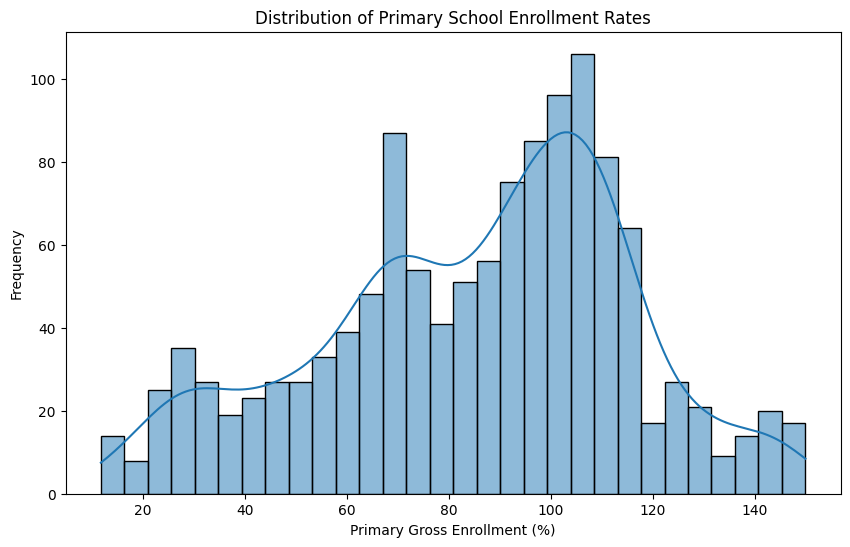

In [197]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=cleaned_data,
    x=target_column,
    bins=30,
    kde=True
)

plt.title('Distribution of Primary School Enrollment Rates')
plt.xlabel('Primary Gross Enrollment (%)')
plt.ylabel('Frequency')

plt.show()

### 5.3 Correlation Analysis

In [198]:
correlation_matrix = cleaned_data[
    numerical_features + [target_column]
].corr()

correlation_matrix

,year,population,population_growth,secondary_enrollment,pupil_teacher_ratio,gdp_per_capita,primary_education_duration,population_age_0_14,primary_enrollment
year,1.000000,0.195497,-0.176297,0.517670,-0.088957,0.110520,-0.045574,-0.349489,0.387960
population,0.195497,1.000000,0.041480,0.159484,-0.093835,-0.060190,-0.112509,-0.039905,0.046670
population_growth,-0.176297,0.041480,1.000000,-0.447909,0.322299,-0.335422,0.000838,0.618309,-0.161197
secondary_enrollment,0.517670,0.159484,-0.447909,1.000000,-0.527464,0.581200,0.047475,-0.763734,0.597755
pupil_teacher_ratio,-0.088957,-0.093835,0.322299,-0.527464,1.000000,-0.366135,-0.046080,0.532451,-0.066952
gdp_per_capita,0.110520,-0.060190,-0.335422,0.581200,-0.366135,1.000000,0.050494,-0.637179,0.441683
primary_education_duration,-0.045574,-0.112509,0.000838,0.047475,-0.046080,0.050494,1.000000,0.060359,0.110164
population_age_0_14,-0.349489,-0.039905,0.618309,-0.763734,0.532451,-0.637179,0.060359,1.000000,-0.369922
primary_enrollment,0.387960,0.046670,-0.161197,0.597755,-0.066952,0.441683,0.110164,-0.369922,1.000000


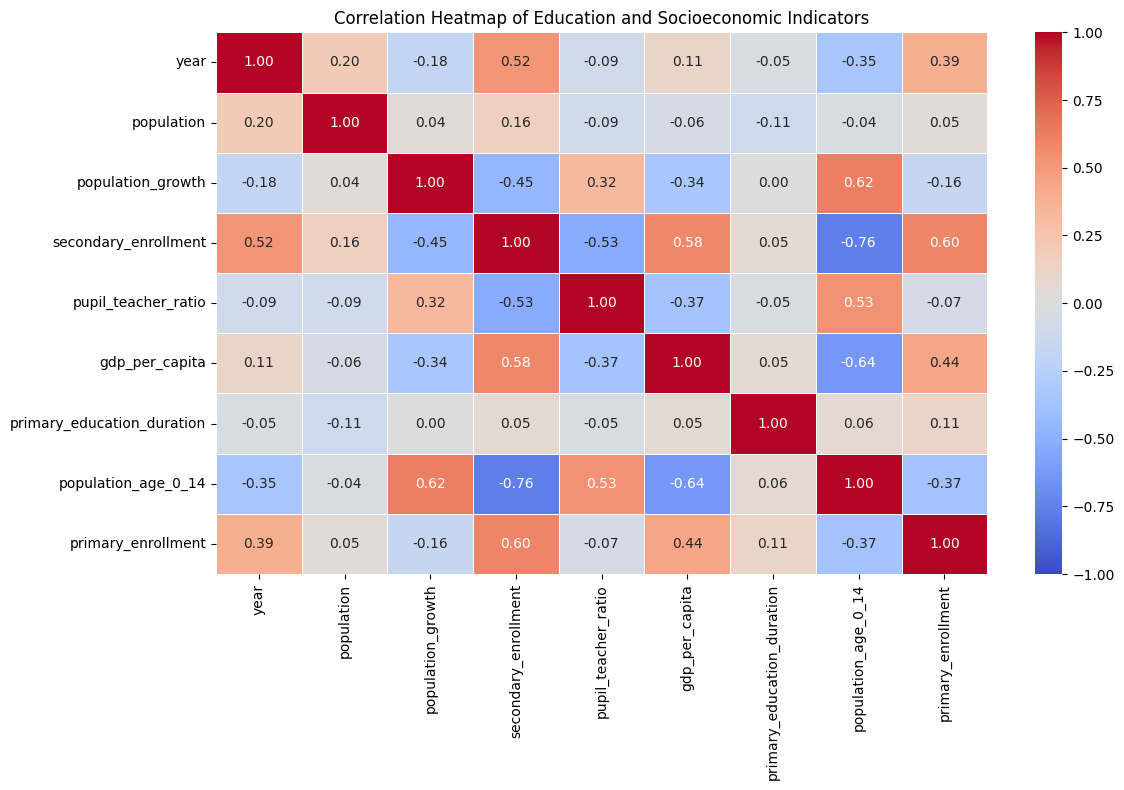

In [199]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Education and Socioeconomic Indicators')

plt.tight_layout()
plt.show()

In [200]:
target_correlations = correlation_matrix[target_column].drop(
    target_column
)

print("Feature correlations with primary enrollment:")

print(
    target_correlations.sort_values(
        key=abs,
        ascending=False
    )
)

Feature correlations with primary enrollment:
secondary_enrollment          0.597755
gdp_per_capita                0.441683
year                          0.387960
population_age_0_14          -0.369922
population_growth            -0.161197
primary_education_duration    0.110164
pupil_teacher_ratio          -0.066952
population                    0.046670
Name: primary_enrollment, dtype: float64


In [201]:
strongest_feature = target_correlations.abs().idxmax()

strongest_correlation = target_correlations[strongest_feature]

print("Most strongly correlated feature:", strongest_feature)

print("Correlation coefficient:", strongest_correlation)

Most strongly correlated feature: secondary_enrollment
Correlation coefficient: 0.5977548867346927


### 5.4 Relationship Between the Strongest Feature and Primary Enrollment

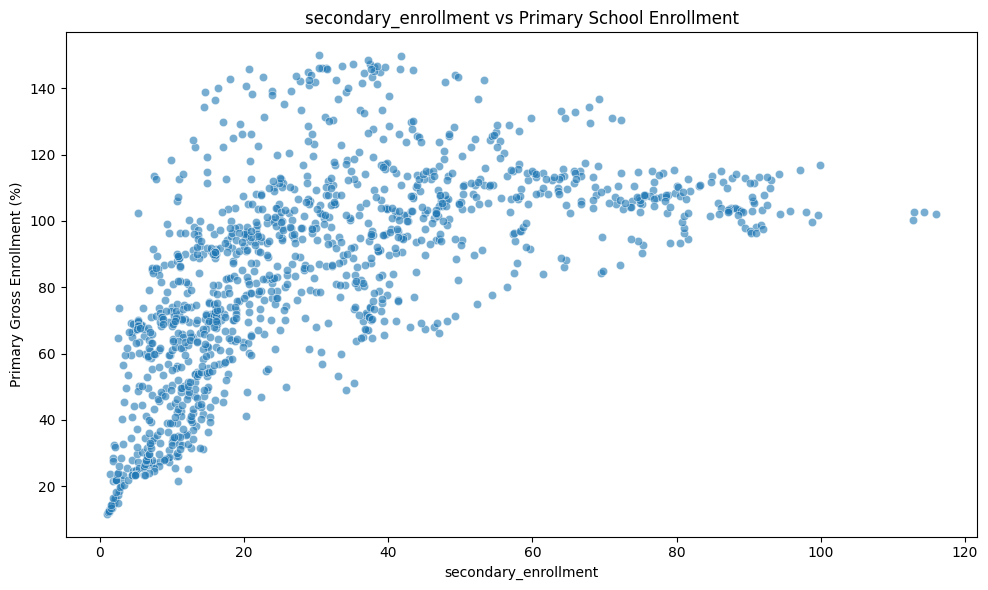

In [202]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=cleaned_data,
    x=strongest_feature,
    y=target_column,
    alpha=0.6
)

plt.title(
    f'{strongest_feature} vs Primary School Enrollment'
)

plt.xlabel(strongest_feature)
plt.ylabel('Primary Gross Enrollment (%)')

plt.tight_layout()
plt.show()

## 6. Feature Engineering and Categorical Encoding

In [203]:
cleaned_data[numerical_features].skew().sort_values(
    ascending=False
)

,0
population,3.201476
gdp_per_capita,2.944339
secondary_enrollment,1.007491
pupil_teacher_ratio,0.500693
year,-0.031730
primary_education_duration,-0.320312
population_growth,-0.736231
population_age_0_14,-1.747686


In [204]:
np.log1p(cleaned_data['population']).describe()

,population
count,1246.000000
mean,15.481389
std,1.520036
min,10.889323
25%,14.439106
50%,15.723239
75%,16.502295
max,18.881759


In [205]:
np.log1p(cleaned_data['gdp_per_capita']).describe()

,gdp_per_capita
count,1246.000000
mean,6.977528
std,0.976715
min,4.887687
25%,6.210494
50%,6.850019
75%,7.619939
max,9.877852


### 6.2 Categorical Encoding

In [206]:
for column in categorical_features:
    print(column)
    print("Unique categories:", cleaned_data[column].nunique())
    print(cleaned_data[column].unique())
    print()

country_code
Unique categories: 50
['DZA' 'AGO' 'BEN' 'BWA' 'BFA' 'BDI' 'CPV' 'CMR' 'CAF' 'TCD' 'COM' 'COD'
 'COG' 'CIV' 'DJI' 'EGY' 'GNQ' 'ERI' 'ETH' 'GAB' 'GMB' 'GHA' 'GIN' 'GNB'
 'KEN' 'LSO' 'LBR' 'MDG' 'MWI' 'MLI' 'MRT' 'MUS' 'MAR' 'MOZ' 'NAM' 'NER'
 'NGA' 'RWA' 'STP' 'SEN' 'SYC' 'SLE' 'ZAF' 'SWZ' 'TZA' 'TGO' 'TUN' 'UGA'
 'ZMB' 'ZWE']

region
Unique categories: 2
['Middle East & North Africa' 'Sub-Saharan Africa']

income_group
Unique categories: 4
['Upper middle income' 'Low income' 'Lower middle income'
 'High income: nonOECD']



### 6.3 Define Input Features and Target Variable

In [207]:
X = cleaned_data[feature_columns].copy()

y = cleaned_data[target_column].copy()

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (1246, 11)
Target shape: (1246,)


In [208]:
X.head()

,year,population,population_growth,secondary_enrollment,pupil_teacher_ratio,gdp_per_capita,primary_education_duration,population_age_0_14,country_code,region,income_group
0,1971,14960109.0,2.779393,10.036360,40.000591,2321.350402,6.0,46.843930,DZA,Middle East & North Africa,Upper middle income
1,1975,16709099.0,2.803819,16.028271,41.964218,3104.493573,6.0,46.730329,DZA,Middle East & North Africa,Upper middle income
2,1976,17190239.0,2.838830,18.395041,40.945961,3270.680356,6.0,46.735982,DZA,Middle East & North Africa,Upper middle income
3,1977,17690184.0,2.866819,21.510111,39.508411,3345.378017,6.0,46.667610,DZA,Middle East & North Africa,Upper middle income
4,1978,18212326.0,2.908871,25.328711,37.581108,3548.900065,6.0,46.549178,DZA,Middle East & North Africa,Upper middle income


In [209]:
y.head()

,primary_enrollment
0,74.015533
1,88.706253
2,91.700302
3,93.652573
4,94.703590


## 7. Data Splitting, Encoding and Standardization

In [210]:
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import FunctionTransformer

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

### 7.2 Train-Test Split

In [211]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [212]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (996, 11)
X_test shape: (250, 11)
y_train shape: (996,)
y_test shape: (250,)


### 7.3 Define Preprocessing Groups

In [213]:
log_features = [
    'population',
    'gdp_per_capita'
]

standard_features = [
    feature for feature in numerical_features
    if feature not in log_features
]

print("Log-transformed features:", log_features)

print("Standardized features:", standard_features)

print("Categorical features:", categorical_features)

Log-transformed features: ['population', 'gdp_per_capita']
Standardized features: ['year', 'population_growth', 'secondary_enrollment', 'pupil_teacher_ratio', 'primary_education_duration', 'population_age_0_14']
Categorical features: ['country_code', 'region', 'income_group']


### 7.4 Numerical Feature Standardization

### 7.5 Build the Preprocessing Pipeline

In [214]:
log_pipeline = Pipeline([
    ('log_transform', FunctionTransformer(np.log1p)),
    ('scaler', StandardScaler())
])

In [215]:
preprocessor = ColumnTransformer(
    transformers=[
        ('log', log_pipeline, log_features),

        ('num', StandardScaler(), standard_features),

        ('cat', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ), categorical_features)
    ]
)

### 7.6 Fit Preprocessing on Training Data

In [216]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)

print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (996, 64)
Processed testing shape: (250, 64)


In [217]:
log_pipeline = Pipeline([
    ('log_transform', FunctionTransformer(
        np.log1p,
        feature_names_out='one-to-one'
    )),
    ('scaler', StandardScaler())
])

In [218]:
print("Means of standardized numerical features:")

print(
    np.round(
        X_train_processed[:, :8].mean(axis=0),
        4
    )
)

print("\nStandard deviations:")

print(
    np.round(
        X_train_processed[:, :8].std(axis=0),
        4
    )
)

Means of standardized numerical features:
[ 0.  0. -0.  0. -0. -0. -0.  0.]

Standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1.]


## 8. Model Training

In [219]:
from sklearn.linear_model import SGDRegressor
from sklearn.linear_model import LinearRegression

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_squared_error

In [220]:
sgd_model = SGDRegressor(
    max_iter=1000,
    tol=1e-3,
    random_state=42
)

linear_model = LinearRegression()

tree_model = DecisionTreeRegressor(
    random_state=42
)

forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [221]:
# Train the model
sgd_model.fit(X_train_processed, y_train)

# Generate predictions
sgd_train_predictions = sgd_model.predict(X_train_processed)
sgd_test_predictions = sgd_model.predict(X_test_processed)

# Calculate MSE
sgd_train_mse = mean_squared_error(
    y_train, sgd_train_predictions
)

sgd_test_mse = mean_squared_error(
    y_test, sgd_test_predictions
)

# Display results
print("SGD Training MSE:", sgd_train_mse)
print("SGD Testing MSE:", sgd_test_mse)

SGD Training MSE: 129.57963783456853
SGD Testing MSE: 159.57640840900254


In [222]:
# Train Linear Regression
linear_model.fit(X_train_processed, y_train)

# Generate predictions
linear_train_predictions = linear_model.predict(X_train_processed)
linear_test_predictions = linear_model.predict(X_test_processed)

# Calculate MSE
linear_train_mse = mean_squared_error(
    y_train, linear_train_predictions
)

linear_test_mse = mean_squared_error(
    y_test, linear_test_predictions
)

# Display results
print("Linear Regression Training MSE:", linear_train_mse)
print("Linear Regression Testing MSE:", linear_test_mse)

Linear Regression Training MSE: 118.3966300820469
Linear Regression Testing MSE: 153.1602418834091


In [223]:
# Train Decision Tree
tree_model.fit(X_train_processed, y_train)

# Generate predictions
tree_train_predictions = tree_model.predict(X_train_processed)
tree_test_predictions = tree_model.predict(X_test_processed)

# Calculate MSE
tree_train_mse = mean_squared_error(
    y_train, tree_train_predictions
)

tree_test_mse = mean_squared_error(
    y_test, tree_test_predictions
)

# Display results
print("Decision Tree Training MSE:", tree_train_mse)
print("Decision Tree Testing MSE:", tree_test_mse)

Decision Tree Training MSE: 0.0
Decision Tree Testing MSE: 184.7445516245936


In [224]:
# Train Random Forest
forest_model.fit(X_train_processed, y_train)

# Generate predictions
forest_train_predictions = forest_model.predict(X_train_processed)
forest_test_predictions = forest_model.predict(X_test_processed)

# Calculate MSE
forest_train_mse = mean_squared_error(
    y_train, forest_train_predictions
)

forest_test_mse = mean_squared_error(
    y_test, forest_test_predictions
)

# Display results
print("Random Forest Training MSE:", forest_train_mse)
print("Random Forest Testing MSE:", forest_test_mse)

Random Forest Training MSE: 8.895156350021253
Random Forest Testing MSE: 62.624452128615275


In [225]:
model_comparison = pd.DataFrame({
    'Model': [
        'SGDRegressor',
        'LinearRegression',
        'DecisionTreeRegressor',
        'RandomForestRegressor'
    ],
    'Training MSE': [
        sgd_train_mse,
        linear_train_mse,
        tree_train_mse,
        forest_train_mse
    ],
    'Testing MSE': [
        sgd_test_mse,
        linear_test_mse,
        tree_test_mse,
        forest_test_mse
    ]
})

model_comparison

,Model,Training MSE,Testing MSE
0,SGDRegressor,129.579638,159.576408
1,LinearRegression,118.396630,153.160242
2,DecisionTreeRegressor,0.000000,184.744552
3,RandomForestRegressor,8.895156,62.624452


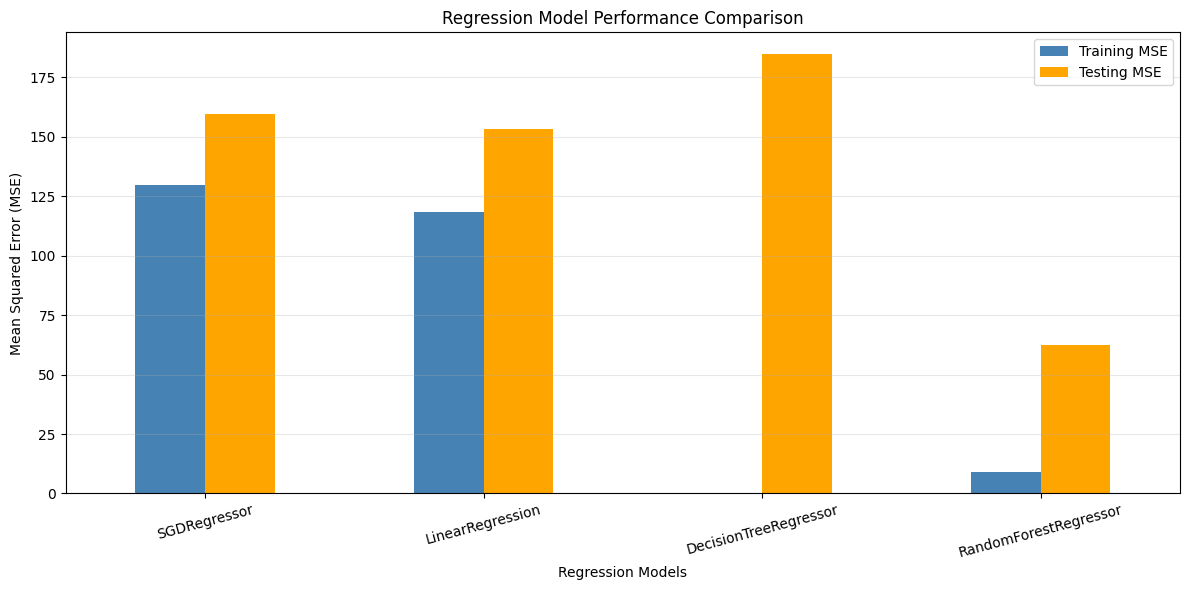

In [226]:
model_comparison.set_index('Model').plot(
    kind='bar',
    figsize=(12, 6),
    color=['steelblue', 'orange']
)

plt.title('Regression Model Performance Comparison')
plt.xlabel('Regression Models')
plt.ylabel('Mean Squared Error (MSE)')
plt.xticks(rotation=15)
plt.legend(['Training MSE', 'Testing MSE'])
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 8.5 Model Performance Interpretation

#### SGDRegressor
- Training MSE: 129.58
- Testing MSE: 159.58

SGDRegressor provides a baseline for gradient descent-based
regression. Its performance may improve through hyperparameter
optimization.

#### Linear Regression
- Training MSE: 118.40
- Testing MSE: 153.16

Linear Regression performs slightly better than SGDRegressor.
However, its prediction errors suggest that linear relationships
may not fully capture the complexity of primary school enrollment.

#### Decision Tree Regressor
- Training MSE: 0.00
- Testing MSE: 184.74

The Decision Tree perfectly fits the training data but produces
the highest testing error. This indicates significant overfitting
and poor generalization to unseen observations.

#### Random Forest Regressor
- Training MSE: 8.90
- Testing MSE: 62.62

Random Forest achieves the lowest testing MSE among the four
models. Its combination of multiple decision trees helps capture
nonlinear relationships and reduces overfitting compared with
an individual Decision Tree.

### Overall Conclusion

Random Forest is the best-performing baseline model, with a
testing MSE of 62.62 and an RMSE of approximately 7.91 percentage
points.

It reduces testing MSE by approximately 60.76% compared with
baseline SGDRegressor.

However, SGD hyperparameter tuning must be completed before
selecting the final model.

### Methodological Limitation

The dataset contains repeated observations of African countries
across different years. Therefore, the random train-test split
evaluates performance on held-out country-year observations
rather than forecasting future enrollment rates or predicting
enrollment in entirely unseen countries.

## 9. SGD Hyperparameter Tuning

In [227]:
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

### 9.1 Hyperparameter Search Strategy

In [228]:
sgd_tuning_pipeline = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('model', SGDRegressor(random_state=42))
])

In [229]:
param_grid = {
    'model__learning_rate': ['constant', 'invscaling'],
    'model__eta0': [0.001, 0.01, 0.05],
    'model__penalty': ['l1', 'l2', 'elasticnet'],
    'model__alpha': [0.0001, 0.001, 0.01],
    'model__max_iter': [500, 1000, 2000]
}

In [230]:
sgd_grid_search = GridSearchCV(
    estimator=sgd_tuning_pipeline,
    param_grid=param_grid,
    scoring='neg_mean_squared_error',
    cv=5,
    n_jobs=-1,
    verbose=1
)

In [231]:
sgd_grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 162 candidates, totalling 810 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('log',
                                                                         Pipeline(steps=[('log_transform',
                                                                                          FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['population',
                                                                          'gdp_per_capita']),
                                                                        ('num',
                                                                         StandardScaler(),
                                                                         ['year',
                                                                          'population_growth',
                                                                          'secondary_enrollment',
                                                                          'pupil_teacher_ratio',
                                                                          'primary_educati...
                                                                                       sparse_output=False),
                                                                         ['country_code',
                                                                          'region',
                                                                          'income_group'])])),
                                       ('model',
                                        SGDRegressor(random_state=42))]),
             n_jobs=-1,
             param_grid={'model__alpha': [0.0001, 0.001, 0.01],
                         'model__eta0': [0.001, 0.01, 0.05],
                         'model__learning_rate': ['constant', 'invscaling'],
                         'model__max_iter': [500, 1000, 2000],
                         'model__penalty': ['l1', 'l2', 'elasticnet']},
             scoring='neg_mean_squared_error', verbose=1)

In [232]:
print("Best Hyperparameters:")

for parameter, value in sgd_grid_search.best_params_.items():
    print(f"{parameter}: {value}")

print("\nBest Cross-Validation MSE:",
      -sgd_grid_search.best_score_)

Best Hyperparameters:
model__alpha: 0.0001
model__eta0: 0.05
model__learning_rate: invscaling
model__max_iter: 500
model__penalty: elasticnet

Best Cross-Validation MSE: 149.42672228090723


In [233]:
optimized_sgd = sgd_grid_search.best_estimator_

In [234]:
optimized_sgd_train_predictions = optimized_sgd.predict(X_train)

optimized_sgd_test_predictions = optimized_sgd.predict(X_test)

In [235]:
optimized_sgd_train_mse = mean_squared_error(
    y_train,
    optimized_sgd_train_predictions
)

optimized_sgd_test_mse = mean_squared_error(
    y_test,
    optimized_sgd_test_predictions
)

print("Optimized SGD Training MSE:", optimized_sgd_train_mse)
print("Optimized SGD Testing MSE:", optimized_sgd_test_mse)

Optimized SGD Training MSE: 130.05241134001932
Optimized SGD Testing MSE: 159.0373731865735


In [236]:
sgd_comparison = pd.DataFrame({
    'Model': [
        'Baseline SGD',
        'Optimized SGD'
    ],
    'Training MSE': [
        sgd_train_mse,
        optimized_sgd_train_mse
    ],
    'Testing MSE': [
        sgd_test_mse,
        optimized_sgd_test_mse
    ]
})

sgd_comparison

,Model,Training MSE,Testing MSE
0,Baseline SGD,129.579638,159.576408
1,Optimized SGD,130.052411,159.037373


### 9.2 Training and Testing Loss Across Epochs

To investigate the convergence behavior of SGDRegressor,
the model is trained incrementally using partial_fit().

Training and testing Mean Squared Error are recorded after
each epoch to visualize how prediction errors change during
training and identify convergence, underfitting, or overfitting.

In [237]:
epoch_sgd = SGDRegressor(
    alpha=0.0001,
    eta0=0.05,
    learning_rate='invscaling',
    penalty='elasticnet',
    random_state=42,
    max_iter=1,
    tol=None
)

In [238]:
epochs = 500

training_losses = []
testing_losses = []

In [239]:
for epoch in range(epochs):

    epoch_sgd.partial_fit(X_train_processed, y_train)

    train_predictions = epoch_sgd.predict(X_train_processed)
    test_predictions = epoch_sgd.predict(X_test_processed)

    train_loss = mean_squared_error(y_train, train_predictions)
    test_loss = mean_squared_error(y_test, test_predictions)

    training_losses.append(train_loss)
    testing_losses.append(test_loss)

In [240]:
print("Initial Training MSE:", training_losses[0])
print("Final Training MSE:", training_losses[-1])

print("Initial Testing MSE:", testing_losses[0])
print("Final Testing MSE:", testing_losses[-1])

print("Total Epochs:", len(training_losses))

Initial Training MSE: 360.12049984199
Final Training MSE: 125.9895303629911
Initial Testing MSE: 348.025395880425
Final Testing MSE: 158.4894816352656
Total Epochs: 500


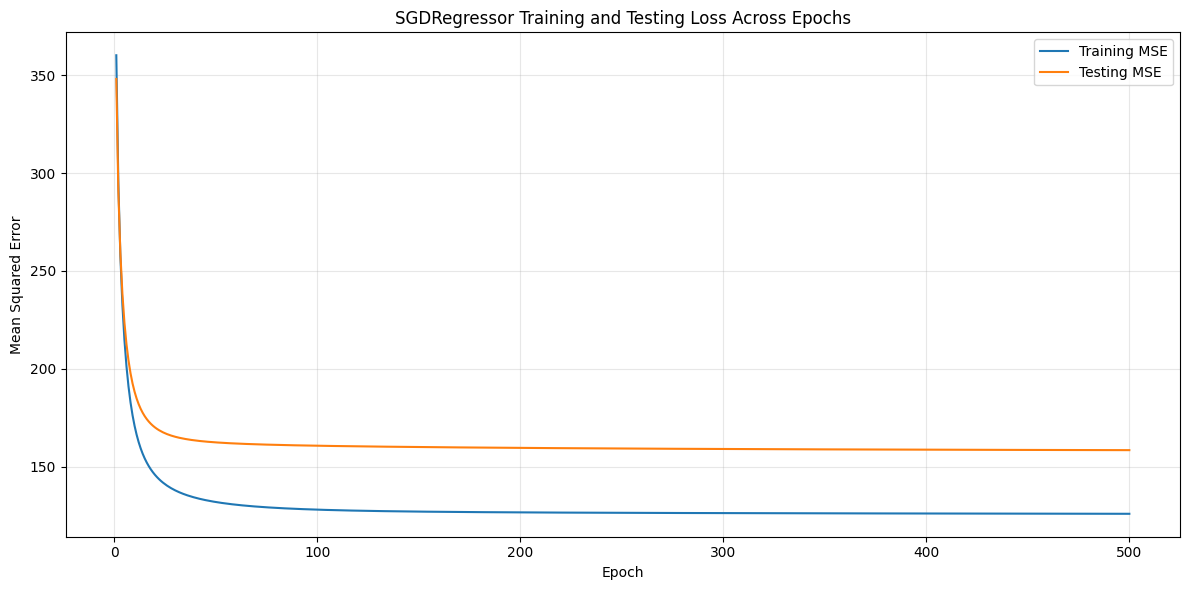

In [241]:
plt.figure(figsize=(12, 6))

plt.plot(
    range(1, epochs + 1),
    training_losses,
    label='Training MSE'
)

plt.plot(
    range(1, epochs + 1),
    testing_losses,
    label='Testing MSE'
)

plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.title('SGDRegressor Training and Testing Loss Across Epochs')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

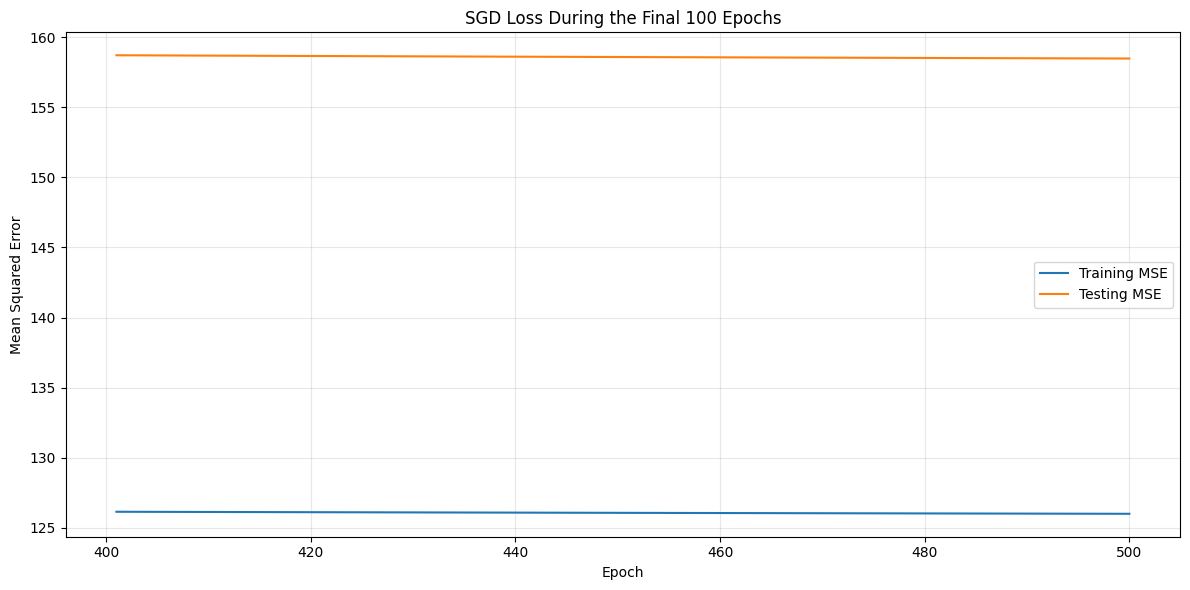

In [242]:
plt.figure(figsize=(12, 6))

plt.plot(
    range(401, 501),
    training_losses[-100:],
    label='Training MSE'
)

plt.plot(
    range(401, 501),
    testing_losses[-100:],
    label='Testing MSE'
)

plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.title('SGD Loss During the Final 100 Epochs')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [243]:
training_loss_reduction = (
    (training_losses[0] - training_losses[-1])
    / training_losses[0]
) * 100

testing_loss_reduction = (
    (testing_losses[0] - testing_losses[-1])
    / testing_losses[0]
) * 100

print("Training Loss Reduction:",
      round(training_loss_reduction, 2), "%")

print("Testing Loss Reduction:",
      round(testing_loss_reduction, 2), "%")

Training Loss Reduction: 65.01 %
Testing Loss Reduction: 54.46 %


### 9.3 Interpretation of SGD Loss Curves

The SGDRegressor was trained incrementally for 500 epochs
using the partial_fit() method. Training and testing Mean
Squared Error were recorded after each epoch to evaluate
the model's learning behavior.

The training loss decreased by 65.01%, while the testing
loss decreased by 54.45%. These reductions demonstrate
that the model improved its predictive performance during
the training process.

The reduction in testing loss indicates that the model
learned relationships that generalize to held-out
observations, rather than simply improving its performance
on the training dataset.

The training loss decreased more than the testing loss,
indicating a difference between training and generalization
performance.

The loss curves provide insight into the effectiveness
of gradient descent and the selected hyperparameters,
including the initial learning rate of 0.05, inverse
scaling learning rate schedule, and Elastic Net
regularization.

Although SGD improved substantially during incremental
training, its overall predictive performance must be
compared with the other regression models before
selecting the final model.

In [244]:
epoch_sgd_train_mse = training_losses[-1]
epoch_sgd_test_mse = testing_losses[-1]

print("Epoch-Based SGD Training MSE:",
      epoch_sgd_train_mse)

print("Epoch-Based SGD Testing MSE:",
      epoch_sgd_test_mse)

Epoch-Based SGD Training MSE: 125.9895303629911
Epoch-Based SGD Testing MSE: 158.4894816352656


In [245]:
all_sgd_comparison = pd.DataFrame({
    'Model': [
        'Baseline SGD',
        'Grid Search Optimized SGD',
        'Epoch-Based SGD'
    ],
    'Training MSE': [
        sgd_train_mse,
        optimized_sgd_train_mse,
        epoch_sgd_train_mse
    ],
    'Testing MSE': [
        sgd_test_mse,
        optimized_sgd_test_mse,
        epoch_sgd_test_mse
    ]
})

all_sgd_comparison

,Model,Training MSE,Testing MSE
0,Baseline SGD,129.579638,159.576408
1,Grid Search Optimized SGD,130.052411,159.037373
2,Epoch-Based SGD,125.989530,158.489482


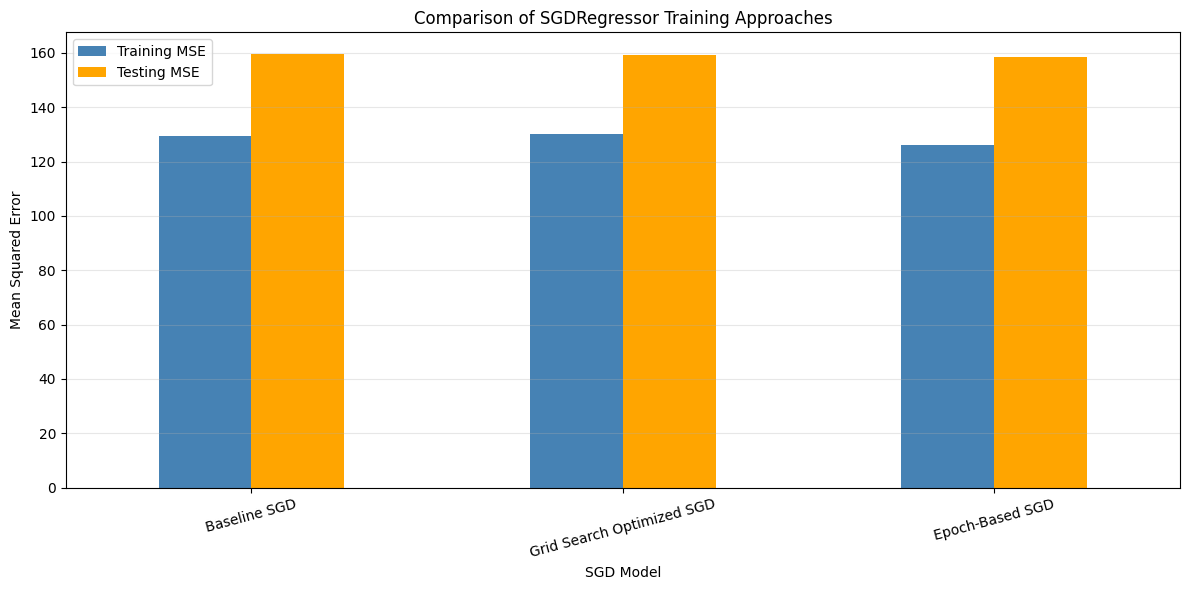

In [246]:
all_sgd_comparison.set_index('Model').plot(
    kind='bar',
    figsize=(12, 6),
    color=['steelblue', 'orange']
)

plt.title('Comparison of SGDRegressor Training Approaches')
plt.xlabel('SGD Model')
plt.ylabel('Mean Squared Error')
plt.xticks(rotation=15)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Final Model Evaluation

This section compares the performance of all regression
models, including the baseline and optimized SGD models.

The models are evaluated using training and testing Mean
Squared Error to identify the most suitable model for
predicting primary school enrollment rates.

The relationship between the most strongly correlated
feature and the target variable is also visualized before
and after fitting a simple linear regression model.

In [247]:
final_comparison = pd.DataFrame({
    'Model': [
        'Baseline SGD',
        'Linear Regression',
        'Decision Tree',
        'Random Forest',
        'Grid Search Optimized SGD',
        'Epoch-Based SGD'
    ],
    'Training MSE': [
        sgd_train_mse,
        linear_train_mse,
        tree_train_mse,
        forest_train_mse,
        optimized_sgd_train_mse,
        epoch_sgd_train_mse
    ],
    'Testing MSE': [
        sgd_test_mse,
        linear_test_mse,
        tree_test_mse,
        forest_test_mse,
        optimized_sgd_test_mse,
        epoch_sgd_test_mse
    ]
})

final_comparison

,Model,Training MSE,Testing MSE
0,Baseline SGD,129.579638,159.576408
1,Linear Regression,118.396630,153.160242
2,Decision Tree,0.000000,184.744552
3,Random Forest,8.895156,62.624452
4,Grid Search Optimized SGD,130.052411,159.037373
5,Epoch-Based SGD,125.989530,158.489482


In [248]:
ranked_models = final_comparison.sort_values(
    by='Testing MSE',
    ascending=True
).reset_index(drop=True)

ranked_models

,Model,Training MSE,Testing MSE
0,Random Forest,8.895156,62.624452
1,Linear Regression,118.396630,153.160242
2,Epoch-Based SGD,125.989530,158.489482
3,Grid Search Optimized SGD,130.052411,159.037373
4,Baseline SGD,129.579638,159.576408
5,Decision Tree,0.000000,184.744552


In [249]:
final_comparison['Training RMSE'] = np.sqrt(
    final_comparison['Training MSE']
)

final_comparison['Testing RMSE'] = np.sqrt(
    final_comparison['Testing MSE']
)

final_comparison

,Model,Training MSE,Testing MSE,Training RMSE,Testing RMSE
0,Baseline SGD,129.579638,159.576408,11.383305,12.632356
1,Linear Regression,118.396630,153.160242,10.881022,12.375793
2,Decision Tree,0.000000,184.744552,0.000000,13.592077
3,Random Forest,8.895156,62.624452,2.982475,7.913561
4,Grid Search Optimized SGD,130.052411,159.037373,11.404052,12.611002
5,Epoch-Based SGD,125.989530,158.489482,11.224506,12.589261


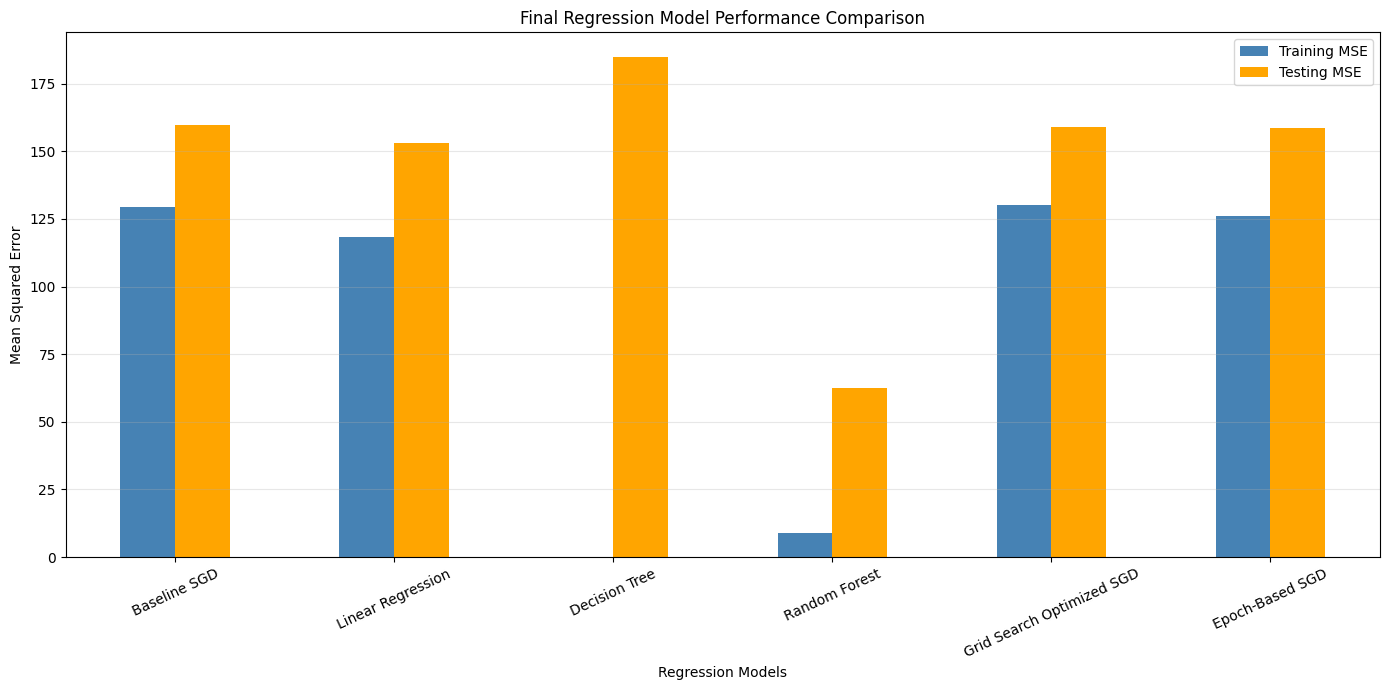

In [250]:
final_comparison.set_index('Model')[
    ['Training MSE', 'Testing MSE']
].plot(
    kind='bar',
    figsize=(14, 7),
    color=['steelblue', 'orange']
)

plt.title('Final Regression Model Performance Comparison')
plt.xlabel('Regression Models')
plt.ylabel('Mean Squared Error')
plt.xticks(rotation=25)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [251]:
best_model_result = final_comparison.loc[
    final_comparison['Testing MSE'].idxmin()
]

print("Best Performing Model:",
      best_model_result['Model'])

print("Training MSE:",
      best_model_result['Training MSE'])

print("Testing MSE:",
      best_model_result['Testing MSE'])

print("Testing RMSE:",
      best_model_result['Testing RMSE'])

Best Performing Model: Random Forest
Training MSE: 8.895156350021253
Testing MSE: 62.624452128615275
Testing RMSE: 7.913561279766227


### 10.1 Final Model Performance Interpretation

The performance comparison demonstrates that Random Forest
achieved the lowest testing Mean Squared Error among all
evaluated regression models.

The model obtained a training MSE of 8.90 and a testing
MSE of 62.62, with a testing RMSE of approximately 7.91
percentage points.

Although SGD hyperparameter tuning and incremental training
improved SGD's testing performance, neither approach
outperformed Random Forest.

The Decision Tree achieved zero training error but had the
highest testing error, indicating significant overfitting.

Random Forest provides stronger predictive performance by
combining multiple decision trees and capturing nonlinear
relationships between socioeconomic and educational
indicators and primary school enrollment rates.

Based on the observed model comparison, Random Forest
is the leading candidate for deployment.

### 10.2 Before-and-After Regression Visualization

To demonstrate the relationship between the most strongly
correlated numerical feature and primary school enrollment,
a scatterplot is generated before fitting a simple linear
regression model.

A fitted regression line is then added to visualize the
relationship learned by the model.

In [252]:
training_correlation_data = X_train[
    numerical_features
].copy()

training_correlation_data[target_column] = y_train

training_correlations = (
    training_correlation_data.corr()[target_column]
    .drop(target_column)
)

strongest_feature = (
    training_correlations.abs().idxmax()
)

strongest_correlation = (
    training_correlations[strongest_feature]
)

print("Most Strongly Correlated Feature:",
      strongest_feature)

print("Correlation Coefficient:",
      strongest_correlation)

Most Strongly Correlated Feature: secondary_enrollment
Correlation Coefficient: 0.5997136465613605


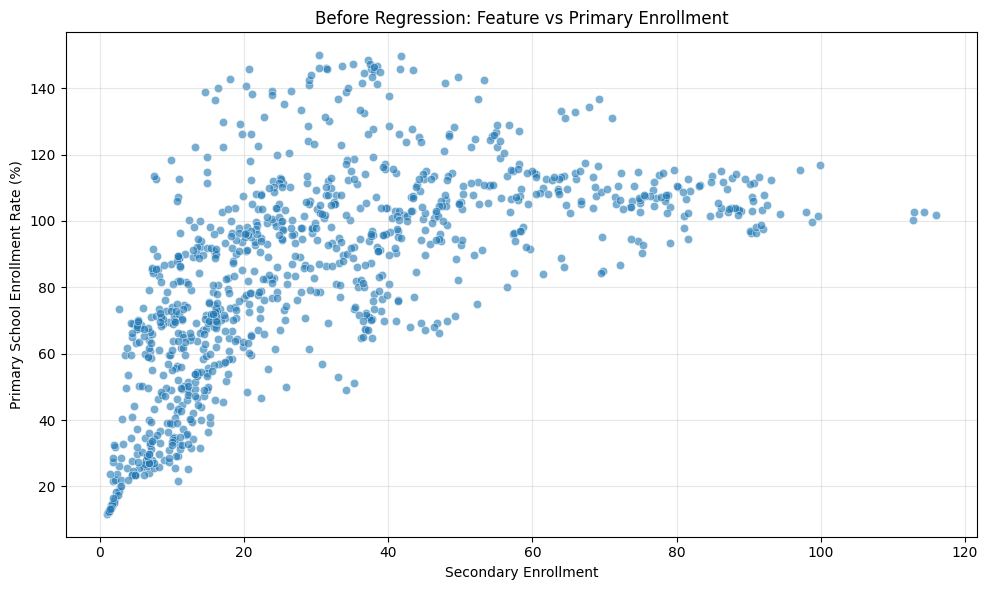

In [253]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_train[strongest_feature],
    y=y_train,
    alpha=0.6
)

plt.xlabel(
    strongest_feature.replace('_', ' ').title()
)

plt.ylabel('Primary School Enrollment Rate (%)')

plt.title(
    'Before Regression: Feature vs Primary Enrollment'
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [254]:
X_train_single = X_train[[strongest_feature]]

X_test_single = X_test[[strongest_feature]]

print("Training feature shape:",
      X_train_single.shape)

print("Testing feature shape:",
      X_test_single.shape)

Training feature shape: (996, 1)
Testing feature shape: (250, 1)


In [255]:
single_feature_model = LinearRegression()

single_feature_model.fit(
    X_train_single,
    y_train
)

print("Regression Coefficient:",
      single_feature_model.coef_[0])

print("Intercept:",
      single_feature_model.intercept_)

Regression Coefficient: 0.7615781666896936
Intercept: 60.5156496526879


In [256]:
feature_range = np.linspace(
    X_train_single[strongest_feature].min(),
    X_train_single[strongest_feature].max(),
    200
)

feature_range_df = pd.DataFrame({
    strongest_feature: feature_range
})

regression_line_predictions = (
    single_feature_model.predict(feature_range_df)
)

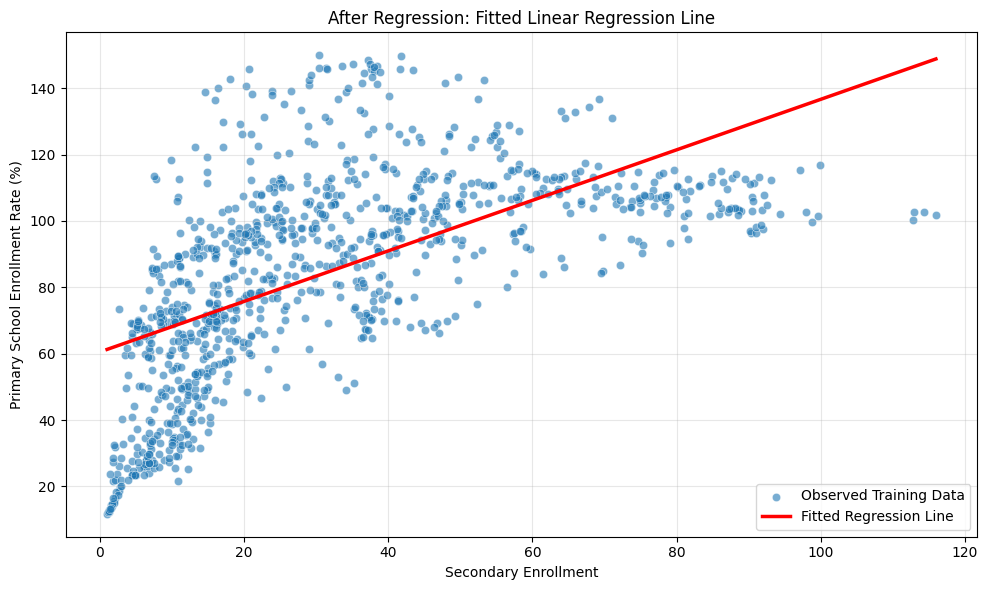

In [257]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_train[strongest_feature],
    y=y_train,
    alpha=0.6,
    label='Observed Training Data'
)

plt.plot(
    feature_range,
    regression_line_predictions,
    color='red',
    linewidth=2.5,
    label='Fitted Regression Line'
)

plt.xlabel(
    strongest_feature.replace('_', ' ').title()
)

plt.ylabel('Primary School Enrollment Rate (%)')

plt.title(
    'After Regression: Fitted Linear Regression Line'
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [258]:
single_train_predictions = (
    single_feature_model.predict(X_train_single)
)

single_test_predictions = (
    single_feature_model.predict(X_test_single)
)

single_train_mse = mean_squared_error(
    y_train,
    single_train_predictions
)

single_test_mse = mean_squared_error(
    y_test,
    single_test_predictions
)

print("Single-Feature Training MSE:",
      single_train_mse)

print("Single-Feature Testing MSE:",
      single_test_mse)

Single-Feature Training MSE: 598.9194977133227
Single-Feature Testing MSE: 590.636465588308


### 10.3 Interpretation of Before-and-After Regression

The before-regression scatterplot illustrates the relationship
between the most strongly correlated numerical feature and
primary school enrollment.

The after-regression scatterplot includes a fitted linear
regression line that represents the relationship learned
from the training data.

The fitted regression model has a coefficient of 0.7616
and an intercept of 60.5156. The positive coefficient
indicates a positive relationship between the selected
feature and primary school enrollment.

The single-feature model achieved a training MSE of
598.92 and a testing MSE of 590.64.

Although the regression line captures the overall positive
relationship, the relatively high prediction errors indicate
that the selected feature alone is insufficient to accurately
predict primary school enrollment.

The multivariate Linear Regression model achieved a
substantially lower testing MSE of 153.16, demonstrating
the importance of incorporating multiple features.

Random Forest achieved the lowest testing MSE of 62.62,
further demonstrating the potential benefits of combining
multiple features and capturing nonlinear relationships.

Overall, the before-and-after regression visualization
demonstrates how linear regression learns a relationship
from observed data, while the performance comparison
highlights the limitations of relying on a single predictor.

In [259]:
print("Strongest Feature:", strongest_feature)
print("Correlation:", strongest_correlation)

Strongest Feature: secondary_enrollment
Correlation: 0.5997136465613605


### 10.3 Interpretation of Before-and-After Regression

Secondary school enrollment was identified as the numerical
feature with the strongest correlation with primary school
enrollment, with a Pearson correlation coefficient of 0.5997.

This indicates a moderately strong positive relationship
between secondary and primary school enrollment rates.

The before-regression scatterplot illustrates the distribution
of observed enrollment rates, while the after-regression
scatterplot includes a fitted linear regression line.

The fitted regression model has a coefficient of 0.7616
and an intercept of 60.5156.

This means that a one-percentage-point increase in secondary
school enrollment is associated with an estimated increase
of 0.7616 percentage points in primary school enrollment.

The single-feature regression model achieved a training
MSE of 598.92 and a testing MSE of 590.64.

Although secondary school enrollment has a positive
relationship with primary school enrollment, the high
prediction errors indicate that it is insufficient as
the only predictor.

The multivariate Linear Regression model achieved a
testing MSE of 153.16, demonstrating the benefits of
incorporating additional educational, demographic and
socioeconomic features.

Random Forest achieved the lowest testing MSE of 62.62,
highlighting the advantages of combining multiple
predictors and capturing nonlinear relationships.

Overall, the before-and-after regression visualization
demonstrates how a linear regression model learns
relationships from observed data while highlighting
the limitations of single-feature prediction.

The observed correlation represents an association
and does not establish a causal relationship between
secondary and primary school enrollment.

## 11. Saving the Best Model and Preprocessing Pipeline

In [260]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold
from sklearn.base import clone
import sklearn
import joblib
import os

In [261]:
random_forest_pipeline = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('model', clone(forest_model))
])

In [262]:
cv_strategy = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

forest_cv_scores = cross_val_score(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

forest_cv_mse = -forest_cv_scores

print("Cross-Validation MSE Scores:")
print(forest_cv_mse)

print("\nMean Cross-Validation MSE:",
      forest_cv_mse.mean())

print("Standard Deviation:",
      forest_cv_mse.std())

Cross-Validation MSE Scores:
[107.93463215  42.88602206  72.99200732 100.56851884 104.95903561]

Mean Cross-Validation MSE: 85.86804319631246
Standard Deviation: 24.822372023476824


In [263]:
random_forest_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('log',
                                                  Pipeline(steps=[('log_transform',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['population',
                                                   'gdp_per_capita']),
                                                 ('num', StandardScaler(),
                                                  ['year', 'population_growth',
                                                   'secondary_enrollment',
                                                   'pupil_teacher_ratio',
                                                   'primary_education_duration',
                                                   'population_age_0_14']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['country_code', 'region',
                                                   'income_group'])])),
                ('model', RandomForestRegressor(random_state=42))])

In [264]:
final_train_predictions = random_forest_pipeline.predict(
    X_train
)

final_test_predictions = random_forest_pipeline.predict(
    X_test
)

final_train_mse = mean_squared_error(
    y_train,
    final_train_predictions
)

final_test_mse = mean_squared_error(
    y_test,
    final_test_predictions
)

print("Final Pipeline Training MSE:", final_train_mse)
print("Final Pipeline Testing MSE:", final_test_mse)

Final Pipeline Training MSE: 8.895156350021253
Final Pipeline Testing MSE: 62.624452128615275


### 11.1 Saving the Trained Model

The Random Forest model and its preprocessing components
are saved together as a single pipeline using Joblib.

Saving the complete pipeline ensures that new input data
undergoes the same transformations used during training,
including logarithmic transformation, standardization,
and categorical encoding.

The saved pipeline will be used by the FastAPI application
to generate primary school enrollment predictions.

In [265]:
api_directory = (
    '/content/drive/MyDrive/'
    'linear_regression_model/summative/API'
)

os.makedirs(api_directory, exist_ok=True)

print("API directory:", api_directory)

API directory: /content/drive/MyDrive/linear_regression_model/summative/API


In [266]:
model_path = os.path.join(
    api_directory,
    'best_model.pkl'
)

joblib.dump(random_forest_pipeline, model_path)

print("Model saved successfully.")
print("Model location:", model_path)

Model saved successfully.
Model location: /content/drive/MyDrive/linear_regression_model/summative/API/best_model.pkl


In [267]:
print("Model file exists:",
      os.path.exists(model_path))

model_size_mb = (
    os.path.getsize(model_path) / (1024 ** 2)
)

print("Model file size:",
      round(model_size_mb, 2), "MB")

Model file exists: True
Model file size: 8.67 MB


In [268]:
loaded_model = joblib.load(model_path)

print("Model loaded successfully.")
print("Loaded model type:", type(loaded_model))

Model loaded successfully.
Loaded model type: <class 'sklearn.pipeline.Pipeline'>


In [269]:
loaded_model_predictions = loaded_model.predict(X_test)

loaded_model_mse = mean_squared_error(
    y_test,
    loaded_model_predictions
)

print("Loaded Model Testing MSE:",
      loaded_model_mse)

print("Predictions Match:",
      np.allclose(
          final_test_predictions,
          loaded_model_predictions
      ))

Loaded Model Testing MSE: 62.624452128615275
Predictions Match: True


In [270]:
print("Scikit-learn version:", sklearn.__version__)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Joblib version:", joblib.__version__)

Scikit-learn version: 1.6.1
Pandas version: 2.2.3
NumPy version: 2.4.6
Joblib version: 1.6.0


In [271]:
original_training_data = X_train.copy()

original_training_data[target_column] = y_train

training_data_path = os.path.join(
    api_directory,
    'training_data.csv'
)

original_training_data.to_csv(
    training_data_path,
    index=False
)

print("Training data saved successfully.")
print("Training data shape:",
      original_training_data.shape)

print("Training data location:",
      training_data_path)

Training data saved successfully.
Training data shape: (996, 12)
Training data location: /content/drive/MyDrive/linear_regression_model/summative/API/training_data.csv


In [272]:
print("Files in API directory:")

for filename in os.listdir(api_directory):
    print(filename)

Files in API directory:
best_model.pkl
training_data.csv


## 12. Prediction Function

In [273]:
sample_input = X_test.iloc[[0]].copy()

sample_input

,year,population,population_growth,secondary_enrollment,pupil_teacher_ratio,gdp_per_capita,primary_education_duration,population_age_0_14,country_code,region,income_group
735,1976,906507.0,1.613262,39.80415,24.67938,2343.41252,6.0,38.501691,MUS,Sub-Saharan Africa,Upper middle income


In [274]:
actual_enrollment = y_test.iloc[0]

print("Actual Primary Enrollment Rate:",
      actual_enrollment)

Actual Primary Enrollment Rate: 103.459518432617


In [275]:
def predict_enrollment(model_path, input_data):
    # Load the saved machine learning pipeline
    model = joblib.load(model_path)

    # Generate a prediction
    prediction = model.predict(input_data)

    # Return the predicted enrollment rate
    return float(prediction[0])

In [276]:
predicted_enrollment = predict_enrollment(
    model_path,
    sample_input
)

print("Predicted Primary Enrollment Rate:",
      round(predicted_enrollment, 2), "%")

Predicted Primary Enrollment Rate: 101.42 %


In [277]:
absolute_error = abs(
    actual_enrollment - predicted_enrollment
)

prediction_comparison = pd.DataFrame({
    'Metric': [
        'Actual Enrollment Rate',
        'Predicted Enrollment Rate',
        'Absolute Prediction Error'
    ],
    'Value': [
        actual_enrollment,
        predicted_enrollment,
        absolute_error
    ]
})

prediction_comparison

,Metric,Value
0,Actual Enrollment Rate,103.459518
1,Predicted Enrollment Rate,101.421206
2,Absolute Prediction Error,2.038313


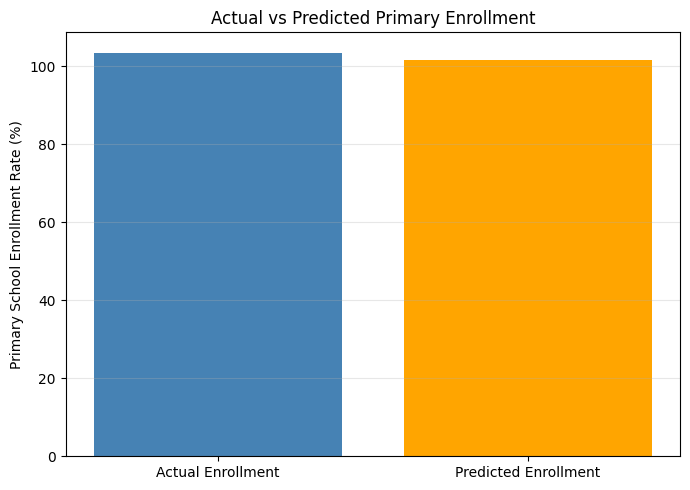

In [278]:
plt.figure(figsize=(7, 5))

plt.bar(
    ['Actual Enrollment', 'Predicted Enrollment'],
    [actual_enrollment, predicted_enrollment],
    color=['steelblue', 'orange']
)

plt.ylabel('Primary School Enrollment Rate (%)')

plt.title('Actual vs Predicted Primary Enrollment')

plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [279]:
original_prediction = random_forest_pipeline.predict(
    sample_input
)[0]

print("Original Pipeline Prediction:",
      original_prediction)

print("Loaded Pipeline Prediction:",
      predicted_enrollment)

print("Predictions Match:",
      np.isclose(
          original_prediction,
          predicted_enrollment
      ))

Original Pipeline Prediction: 101.42120590209962
Loaded Pipeline Prediction: 101.42120590209962
Predictions Match: True


### 12.1 Prediction Function Interpretation

The saved Random Forest pipeline was successfully loaded
using Joblib and used to predict primary school enrollment
for a selected observation from the test dataset.

The original pipeline generated a prediction of 101.4212%,
and the loaded pipeline generated an identical prediction
of 101.4212%.

The prediction consistency test returned True, confirming
that saving and loading the pipeline preserved its
predictive behavior.

The saved pipeline automatically applies the preprocessing
steps, including logarithmic transformation, standardization,
and categorical encoding, before generating a prediction.

The predicted enrollment rate exceeds 100% because the
target variable represents gross primary school enrollment,
which includes students outside the official primary
school age range.

This successful prediction demonstrates that the saved
model is ready for integration into the FastAPI application,
where users will be able to submit input features and
receive enrollment predictions without retraining the model.

## 13. Conclusion

### 13.1 Project Overview

This project investigated the application of machine learning to predict primary school enrollment rates in African countries using educational, demographic, and socioeconomic indicators. The objective was to develop a reliable regression model that could support data-driven decision-making in education planning and provide insights into factors associated with school enrollment across Africa.

### 13.2 Dataset and Data Preparation

The dataset was obtained from the World Bank Education Statistics dataset available on Kaggle. After filtering African countries, selecting relevant indicators, transforming the dataset into a country-year format, and removing incomplete observations, the final dataset contained 1,246 observations representing 50 African countries between 1970 and 2016.

The final dataset consisted of 11 input features, including eight numerical features and three categorical features, with primary school enrollment as the continuous target variable.

Data preprocessing involved logarithmic transformation of population and GDP per capita, standardization of numerical features, and one-hot encoding of categorical variables. The dataset was divided into 996 training observations and 250 testing observations using an 80:20 split. Preprocessing transformations were fitted exclusively on the training data to prevent data leakage during model training.

### 13.3 Exploratory Data Analysis

Exploratory data analysis was conducted using distribution plots, correlation heatmaps, and scatterplots to understand the characteristics of the dataset and relationships between variables.

Secondary school enrollment was identified as the numerical feature with the strongest correlation with primary school enrollment in the training dataset, with a Pearson correlation coefficient of 0.5997. This indicated a moderately strong positive relationship.

However, the single-feature linear regression model achieved a testing MSE of 590.64, demonstrating that secondary school enrollment alone was insufficient to accurately predict primary school enrollment. This highlighted the importance of incorporating multiple educational, demographic, and socioeconomic indicators.

### 13.4 Model Training and Performance

Four regression algorithms were trained and evaluated: SGDRegressor, Linear Regression, Decision Tree Regressor, and Random Forest Regressor.

The following table summarizes the final model performance:

| Model | Training MSE | Testing MSE |
|---|---:|---:|
| Baseline SGDRegressor | 129.58 | 159.58 |
| Linear Regression | 118.40 | 153.16 |
| Decision Tree Regressor | 0.00 | 184.74 |
| Random Forest Regressor | 8.90 | 62.62 |
| Grid Search Optimized SGD | 130.05 | 159.04 |
| Epoch-Based SGD | 125.99 | 158.49 |

Hyperparameter optimization was performed on SGDRegressor using GridSearchCV to investigate different learning rates, regularization techniques, regularization strengths, and maximum iteration values.

Incremental training over 500 epochs was also conducted using the partial_fit() method. The training loss decreased by 65.01%, while the testing loss decreased by 54.45%, demonstrating the effectiveness of iterative optimization.

Although SGD optimization improved predictive performance, Random Forest achieved the lowest testing MSE among all evaluated models.

### 13.5 Best Model Selection

Random Forest Regressor was selected as the final model based on its superior observed testing performance.

The model achieved:

- Training MSE: 8.8952
- Testing MSE: 62.6245
- Testing RMSE: 7.9136 percentage points

Random Forest demonstrated stronger predictive performance than the other evaluated models by combining multiple decision trees and capturing nonlinear relationships between the input features and primary school enrollment.

The Decision Tree model achieved zero training error but substantially higher testing error, indicating significant overfitting. Random Forest reduced this problem through ensemble learning, although the difference between its training and testing errors suggests that some overfitting may remain.

### 13.6 Model Saving and Deployment Readiness

The selected Random Forest model was combined with its preprocessing components into a single Scikit-learn pipeline.

The complete pipeline was saved using Joblib as best_model.pkl, ensuring that future predictions apply the same preprocessing transformations used during training.

A prediction function was implemented to load the saved pipeline and generate a prediction using a selected test observation.

Both the original pipeline and the loaded pipeline produced an identical prediction of 101.4212%, confirming that model serialization preserved the predictive behavior.

The saved pipeline is ready for integration into a FastAPI application, which will provide prediction and retraining endpoints. The API will subsequently be connected to a Flutter mobile application to make enrollment predictions accessible through a user-friendly interface.

### 13.7 Limitations

Despite the promising results, several limitations should be considered.

First, the dataset contains historical observations ending in 2016, which may not fully reflect current educational conditions across African countries.

Second, removing incomplete observations reduced the available dataset substantially and may have introduced selection bias by excluding countries and years with limited data availability.

Third, the random training and testing split may include observations from the same countries in both datasets. Therefore, the reported performance does not necessarily demonstrate the model's ability to generalize to entirely unseen countries or predict future enrollment trends.

Fourth, the difference between Random Forest's training and testing MSE indicates that further model optimization may be beneficial.

Finally, the relationships identified between the input features and primary school enrollment represent statistical associations rather than causal relationships. The model should therefore be used as a decision-support tool rather than as a definitive explanation of educational outcomes.

### 13.8 Future Improvements

Future work could improve the model by incorporating more recent education statistics, additional indicators, and alternative approaches to handling missing values.

Random Forest hyperparameters could also be optimized to improve generalization and reduce overfitting.

Furthermore, country-based and chronological validation strategies could be introduced to evaluate the model's ability to generalize to unseen countries and future years.

Additional socioeconomic indicators, such as government education expenditure, poverty levels, school infrastructure, and access to educational resources, could potentially improve predictive accuracy.

The next stage of the project involves deploying the trained model through FastAPI and integrating it with a Flutter mobile application, enabling users to generate enrollment predictions and update the model using newly available data.

### 13.9 Final Remarks

Overall, this project demonstrates the potential of machine learning to support education planning and data-driven decision-making in Africa.

The results show that combining multiple educational, demographic, and socioeconomic indicators provides substantially better predictive performance than relying on a single feature.

By developing, evaluating, optimizing, and saving a complete machine learning pipeline, this project establishes a foundation for an accessible predictive system that can support educational research, resource planning, and informed decision-making.

The project also demonstrates the practical application of the complete machine learning workflow, from data preparation and exploratory analysis to model evaluation, serialization, and preparation for real-world deployment.